# PubMedCLIP + QCR 재현 (Expert-CFG Table 1의 PubMedCLIP 행)

| Dataset | 시각 인코더 | 논문 Open / Closed / Overall |
|---|---|---|
| VQA-RAD (train 3064 / test 451) | PubMedCLIP RN50 + AE | 60.1 / 80.0 / 72.1 |
| SLAKE 영어 (train 4919 / test 1061) | PubMedCLIP ViT-B/32 + AE | 78.4 / 82.5 / 80.1 |

- **학습 코드**: 공식 [sarahESL/PubMedCLIP `QCR_PubMedCLIP`](https://github.com/sarahESL/PubMedCLIP/tree/bdecf3c5a21b68200a02dc05455b3882a23206a2/QCR_PubMedCLIP)
  (commit `bdecf3c`)을 clone하고 **저자의 config 그대로** `main/main.py`를 실행합니다.
  GloVe+GRU, BAN(glimpse 10), TCR 유형 분류기, AE(재구성 손실 0.001), Adamax lr 1e-3, batch 16, 200 epoch, seed 88.
- 바뀌는 것은 최신 PyTorch/pandas/Python에서 돌리기 위한 **호환성 패치뿐**입니다. 목록과 이유는 3번 셀에서 출력되고 `run_info.json`에도 저장됩니다.
- **가중치**: 저자 HF [`sarahESL/PubMedCLIP`](https://huggingface.co/sarahESL/PubMedCLIP) (`PubMedCLIP_RN50.pth`, `PubMedCLIP_ViT32.pth`).
- **VQA-RAD 3064/451**: 원래 QCR 저자 저장소 [Awenbocc/med-vqa](https://github.com/Awenbocc/med-vqa) `data/`.
  PubMedCLIP QCR 코드는 이 묶음의 라벨 공간(487 = closed 56 + open 431)과 사전(1177단어, 동봉된 type classifier와 일치)을 전제로 합니다.
  train/test JSON·이미지 색인·AE는 HF [`aiozai/MEVF`](https://huggingface.co/datasets/aiozai/MEVF)와 바이트 단위로 같습니다.
  빠진 `images250x250.pkl`만 PubMedCLIP 스크립트로 만듭니다.
- **SLAKE**: 저자 HF [`BoKelvin/SLAKE`](https://huggingface.co/datasets/BoKelvin/SLAKE)에 PubMedCLIP `lib/utils/run.sh` 전처리를 그대로 적용합니다.
  GloVe와 AE는 HF `aiozai/MEVF`에서 받습니다.
- 모든 외부 파일은 revision/commit으로 고정하고 SHA-256을 검사합니다. Google Drive는 쓰지 않습니다.

**평가 방식(저자 코드 그대로)**: 매 epoch마다 **test set**으로 평가하고, 가장 높은 overall epoch의 점수를 보고합니다.
즉 test로 epoch를 고르는 방식이며, 이 노트북은 재현을 위해 이를 바꾸지 않습니다. 마지막 epoch 점수도 함께 기록합니다.
config 이름의 `nondeterministic`처럼 cuDNN 때문에 같은 seed로도 실행마다 결과가 조금 다릅니다. 여러 번 돌리려면 `NUM_RUNS`를 늘리세요.

GPU 런타임에서 위부터 실행하세요. 실행마다 200 epoch가 걸립니다(T4 기준 수 시간). 원 코드에는 이어서 학습하는 기능이 없습니다.


## 1. 환경 설치

Colab 기본 torch/torchvision/pandas/transformers를 그대로 씁니다. OpenAI `clip` 패키지는 commit으로 고정합니다.


In [4]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'yacs==0.1.8', 'ftfy', 'regex',
    'setuptools<81',  # clip imports pkg_resources
    'git+https://github.com/openai/CLIP.git@d05afc436d78f1c48dc0dbf8e5980a9d471f35f6'])
import torch
assert torch.cuda.is_available(), '런타임 > 런타임 유형 변경 > GPU'
print(torch.__version__, torch.cuda.get_device_name(0))


2.11.0+cu130 Tesla T4


## 2. 포팅 코드

저장소의 `qcr_port.py`가 그대로 들어 있습니다.


In [5]:
from pathlib import Path
import sys
CODE_ROOT = Path('/content/qcr_port_code')
CODE_ROOT.mkdir(exist_ok=True)
(CODE_ROOT / 'qcr_port.py').write_text('"""Run the official PubMedCLIP QCR code on a current Colab GPU runtime.\n\nThe official code (sarahESL/PubMedCLIP, QCR_PubMedCLIP, pinned commit) is cloned and\nonly environment-compatibility edits are applied (see PATCHES). Model, loss, optimizer,\ndata preprocessing scripts and configs are the authors\' own. Every external asset is\npinned to an exact revision (HF revision or git commit) and verified by SHA-256.\n"""\nimport hashlib\nimport json\nimport re\nimport shutil\nimport subprocess\nimport sys\nimport zipfile\nfrom pathlib import Path, PurePosixPath\n\nQCR_REPO = \'https://github.com/sarahESL/PubMedCLIP.git\'\nQCR_COMMIT = \'bdecf3c5a21b68200a02dc05455b3882a23206a2\'\n\n# repo, repo_type, revision, filename, sha256\nASSETS = {\n    \'mevf_rad\': (\'aiozai/MEVF\', \'dataset\', \'7b3bd1b1ef8965eb35ff61a1f6fada25377765ea\', \'data_RAD.zip\',\n                 \'b75d664c3dac7096a695e3a8a2b309769804f5add7e72b15e037ea9e5b839a9f\'),\n    \'slake_imgs\': (\'BoKelvin/SLAKE\', \'dataset\', \'a9083ce6c34ac3ffb17671a605962924d8a8f9e9\', \'imgs.zip\',\n                   \'44eb7d9214e1ac5b7946e237b669401866df9114fd9a3618c5a84fbffcded0b0\'),\n    \'slake_train\': (\'BoKelvin/SLAKE\', \'dataset\', \'a9083ce6c34ac3ffb17671a605962924d8a8f9e9\', \'train.json\',\n                    \'7a9fb81f9d7bb145c3d7e9bc8d3b9016ba18b6539ea5031a53bae8fd3cd991c3\'),\n    \'slake_test\': (\'BoKelvin/SLAKE\', \'dataset\', \'a9083ce6c34ac3ffb17671a605962924d8a8f9e9\', \'test.json\',\n                   \'6be8f7b4c5a46cdbc713a5210a25b6ed5aa1fd1574c83cefb4f998131f17c2c3\'),\n    \'RN50\': (\'sarahESL/PubMedCLIP\', \'model\', \'c5885a5c0ba8ac8d86341e57c8466e49783874c1\', \'PubMedCLIP_RN50.pth\',\n             \'bb8b2bfd7f6e38fb7fb1861d969e4df862776f605aede4ecb200d2e72f9d4c6a\'),\n    \'ViT\': (\'sarahESL/PubMedCLIP\', \'model\', \'c5885a5c0ba8ac8d86341e57c8466e49783874c1\', \'PubMedCLIP_ViT32.pth\',\n            \'56d244ea2e547b59fd0357eb17d481240eeb21590e5bae2c91ea0a55de82d9c6\'),\n}\n\n# Expert-CFG Table 1 PubMedCLIP rows = PubMedCLIP paper Table 1 (QCR + AE): [open, closed, overall].\nRUNS = {\n    \'rad\': {\'encoder\': \'RN50\', \'config\': \'qcr_pubmedclipRN50_ae_rad_16batchsize_withtfidf_nondeterministic.yaml\',\n            \'paper\': [60.10, 80.00, 72.10], \'counts\': {\'train\': 3064, \'test\': 451}},\n    \'slake\': {\'encoder\': \'ViT\', \'config\': \'qcr_pubmedclipViT_ae_slake_16batchsize_withtfidf_nondeterministic.yaml\',\n              \'paper\': [78.40, 82.50, 80.10], \'counts\': {\'train\': 4919, \'test\': 1061}},\n}\n\n# The original QCR authors\' repository ships the prepared VQA-RAD bundle (data/). PubMedCLIP\'s\n# QCR code at QCR_COMMIT hard-codes its label space (487 = 56 closed + 431 open, open labels\n# indexed locally) and its type classifier was trained on that 1177-word dictionary; the\n# PubMedCLIP create_label.py/create_dictionary.py would instead produce 64+483 labels and\n# 1259 words, which the code cannot load. Train/test JSON, imgid2idx, auto-encoder and\n# images128 are byte-identical to the MEVF bundle on HF (aiozai/MEVF data_RAD.zip).\nORIGINAL_QCR_REPO = \'https://github.com/Awenbocc/med-vqa.git\'\nORIGINAL_QCR_COMMIT = \'0cca6811e38cf54aff6a7cce3442296d07875e64\'\nRAD_SHA256 = {\n    \'trainset.json\': \'3b0567673ae224b6489ca1bc4ce05cda642223d5cf4f17db8fbf7010c872e00f\',\n    \'testset.json\': \'3d32a047592cb680e18054030b38b1a44d6b17105fc62d3088c8655d56a00ced\',\n    \'imgid2idx.json\': \'4ee2f8ebc4adf3700c10307c0b3daac3edafaf08717b4d20eef423228e316257\',\n    \'dictionary.pkl\': \'35a01367a5d5a4417d6f99c045bf8f3ccca51bb48da0e37e1aae38590cc40504\',\n    \'glove6b_init_300d.npy\': \'7b70281a90e0b141d4655481718a99f9d3f09da23d2f10608e874173c1057bf1\',\n    \'embed_tfidf_weights.pkl\': \'0bb3cbb06714f8987886abffe69e0d38bf312ce7b9406b2b804915a568fcfd27\',\n    \'images128x128.pkl\': \'136cffd2c2222993c9cc7035ded0fa11d7ce1cae37ab0baaa951f85a002c6e6f\',\n    \'pretrained_ae.pth\': \'f2fb0fdc6d014fb49b85fcd2029902e14db9b42d21f3718d1a07d7082960bd05\',\n    \'cache/close_label2ans.pkl\': \'b50f9d24cb6a54599ffda7b371f3f42419be42aa5c58f9069d531cf7ffe9d863\',\n    \'cache/open_label2ans.pkl\': \'965340e4b4e9ad152e7d055987f25cafe630666d70b6fee795ccc526d28a1f4a\',\n    \'cache/trainval_ans2label.pkl\': \'daaebd434b2d1e06d79aebf24d750adca76dcb1e4548ada83a16aee0848b6b77\',\n    \'cache/trainval_label2ans.pkl\': \'22bd133cc95f2d2c25973db5e463e0c3a603c84ea4404bec1020299b8d587e83\',\n    \'cache/train_openclose_target.pkl\': \'2b99f7ade3d38d0fb5da77a4af65f8afb505f1afb5657e2b23623126c602edf5\',\n    \'cache/test_openclose_target.pkl\': \'4df33f0095ea260d91b6525d3318281c8313cebf28f0dd5c56d363635342c09b\',\n}\n\n# Inserted into lib/utils/utils.py. Globals were audited with pickletools on the pinned file.\nTFIDF_LOADER = \'\'\'string_classes = (str, bytes)\nimport pickle as _pickle\nimport types as _types\ntry:  # referenced by the PyTorch 0.4 pickle of embed_tfidf_weights.pkl\n    import torch.nn.backends.thnn\nexcept ImportError:\n    import sys as _sys\n    _thnn = _types.ModuleType(\'torch.nn.backends.thnn\')\n    _thnn._get_thnn_function_backend = lambda: None\n    _sys.modules[\'torch.nn.backends.thnn\'] = _thnn\n_TFIDF_GLOBALS = {(\'collections\', \'OrderedDict\'), (\'language_model\', \'WordEmbedding\'),\n                  (\'language.language_model\', \'WordEmbedding\'),  # file written by QCR itself (SLAKE)\n                  (\'__builtin__\', \'set\'), (\'builtins\', \'set\'),\n                  (\'torch\', \'FloatStorage\'), (\'torch._utils\', \'_rebuild_parameter\'),\n                  (\'torch._utils\', \'_rebuild_tensor_v2\'), (\'torch.nn.backends.thnn\', \'_get_thnn_function_backend\'),\n                  (\'torch.nn.modules.dropout\', \'Dropout\'), (\'torch.nn.modules.sparse\', \'Embedding\')}\nclass _AllowlistUnpickler(_pickle.Unpickler):\n    def find_class(self, module, name):\n        if (module, name) not in _TFIDF_GLOBALS:\n            raise _pickle.UnpicklingError(\'Blocked global in embed_tfidf_weights.pkl: %s.%s\' % (module, name))\n        return super().find_class(module, name)\n_tfidf_pickle = _types.ModuleType(\'qcr_allowlist_pickle\')\n_tfidf_pickle.Unpickler = _AllowlistUnpickler\n_tfidf_pickle.load = lambda f, **kw: _AllowlistUnpickler(f, **kw).load()\n\'\'\'\n\n# (file, old, new, reason). Each `old` must occur exactly once in the pinned commit.\nPATCHES = [\n    (\'lib/utils/utils.py\', \'from torch._six import string_classes\\n\', TFIDF_LOADER,\n     \'torch._six was removed in PyTorch 2; also defines the allowlisted loader used below\'),\n    (\'lib/utils/utils.py\', \'collections.Mapping)\', \'collections.abc.Mapping)\', \'Python 3.10 removed collections.Mapping\'),\n    (\'lib/utils/utils.py\', \'collections.Sequence)\', \'collections.abc.Sequence)\', \'Python 3.10 removed collections.Sequence\'),\n    (\'lib/utils/utils.py\', \'w_emb = torch.load(f)\\n\',\n     \'w_emb = torch.load(f, weights_only=False, pickle_module=_tfidf_pickle)\\n\',\n     \'embed_tfidf_weights.pkl is a PyTorch-0.4 pickled nn.Module; PyTorch>=2.6 defaults to weights_only=True. \'\n     \'Load it with an unpickler that only allows the audited classes\'),\n    (\'lib/utils/utils.py\', \'torch.sparse.FloatTensor(torch.LongTensor(inds), torch.FloatTensor(vals))\',\n     \'torch.sparse_coo_tensor(torch.LongTensor(inds), torch.FloatTensor(vals))\', \'legacy sparse constructor\'),\n    (\'lib/utils/create_label.py\', \'qa_pairs = train_qa_pairs.append(val_qa_pairs)\\n    qa_pairs[\\\'answer\\\'] = qa_pairs[\\\'answer\\\'].apply(lambda x: str(x))\\n\\n    for id\',\n     \'qa_pairs = pd.concat([train_qa_pairs, val_qa_pairs])\\n    qa_pairs[\\\'answer\\\'] = qa_pairs[\\\'answer\\\'].apply(lambda x: str(x))\\n\\n    for id\',\n     \'DataFrame.append was removed in pandas 2\'),\n    (\'lib/utils/create_label.py\', \'qa_pairs = train_qa_pairs.append(val_qa_pairs)\\n    qa_pairs[\\\'answer\\\'] = qa_pairs[\\\'answer\\\'].apply(lambda x: str(x))\\n    qa_pairs_open\',\n     \'qa_pairs = pd.concat([train_qa_pairs, val_qa_pairs])\\n    qa_pairs[\\\'answer\\\'] = qa_pairs[\\\'answer\\\'].apply(lambda x: str(x))\\n    qa_pairs_open\',\n     \'DataFrame.append was removed in pandas 2\'),\n    (\'lib/utils/create_label.py\', \'df = train_qa_pairs.append(val_qa_pairs)\', \'df = pd.concat([train_qa_pairs, val_qa_pairs])\',\n     \'DataFrame.append was removed in pandas 2\'),\n    (\'lib/utils/create_img2idx.py\', \'df = train_en.append(val_en)\', \'df = pd.concat([train_en, val_en])\',\n     \'DataFrame.append was removed in pandas 2\'),\n    (\'lib/BAN/multi_level_model.py\',\n     "            self.clip, _ = clip.load(cfg.TRAIN.VISION.CLIP_VISION_ENCODER, jit=False)\\n"\n     "            if not cfg.TRAIN.VISION.CLIP_ORG:\\n"\n     "                checkpoint = torch.load(cfg.TRAIN.VISION.CLIP_PATH)\\n"\n     "                self.clip.load_state_dict(checkpoint[\'state_dict\'])\\n",\n     "            if not cfg.TRAIN.VISION.CLIP_ORG:\\n"\n     "                checkpoint = torch.load(cfg.TRAIN.VISION.CLIP_PATH, map_location=\'cpu\')\\n"\n     "                # Same as clip.load(name) + load_state_dict: build_model() casts to fp16 and the\\n"\n     "                # PubMedCLIP weights are copied into those fp16 parameters before .float().\\n"\n     "                self.clip = clip.model.build_model(checkpoint[\'state_dict\']).to(device)\\n"\n     "                self.clip.load_state_dict(checkpoint[\'state_dict\'])\\n"\n     "            else:\\n"\n     "                self.clip, _ = clip.load(cfg.TRAIN.VISION.CLIP_VISION_ENCODER, jit=False)\\n",\n     \'clip.load(name) first downloads OpenAI weights (openaipublic.azureedge.net CDN) that are immediately \'\n     \'overwritten; build the identical architecture from the PubMedCLIP state dict instead\'),\n    (\'main/classifier.py\', \'nn.Dropout(cfg.TRAIN.DROPOUT, inplace=True)\', \'nn.Dropout(cfg.TRAIN.DROPOUT, inplace=False)\',\n     \'current autograd rejects in-place dropout on the saved ReLU output; out-of-place dropout gives the same \'\n     \'forward values and gradients (dropped units get zero gradient either way)\'),\n    (\'main/train.py\',\n     "                utils.save_model(model_path, model, best_epoch, eval_score, open_score, close_score, optim)\\n",\n     "                utils.save_model(model_path, model, best_epoch, eval_score, open_score, close_score, optim)\\n"\n     "                if os.environ.get(\'QCR_KEEP_ALL_BEST\', \'0\') != \'1\':\\n"\n     "                    for old in os.listdir(ckpt_path):\\n"\n     "                        if old.endswith(\'_best.pth\') and old != os.path.basename(model_path):\\n"\n     "                            os.remove(os.path.join(ckpt_path, old))\\n",\n     \'each improvement saves a ~1 GB checkpoint (CLIP + optimizer); keep only the newest one so 200 epochs fit \'\n     \'on Colab disk (file handling only; QCR_KEEP_ALL_BEST=1 restores the original behaviour)\'),\n    (\'main/main.py\', \'    torch.autograd.set_detect_anomaly(True)\\n\',\n     \'    torch.autograd.set_detect_anomaly(os.environ.get("QCR_DETECT_ANOMALY", "0") == "1")\\n\',\n     \'anomaly detection is a debugging aid (no numerical effect) that slows training several times; \'\n     \'set QCR_DETECT_ANOMALY=1 to restore it\'),\n]\n\n\ndef sha256(path, chunk=1 << 22):\n    h = hashlib.sha256()\n    with open(path, \'rb\') as f:\n        for block in iter(lambda: f.read(chunk), b\'\'):\n            h.update(block)\n    return h.hexdigest()\n\n\ndef run(cmd, cwd=None, env=None):\n    import os\n    print(\'$\', \' \'.join(map(str, cmd)), flush=True)\n    # The authors\' scripts open GloVe/JSON with the platform default encoding.\n    env = dict(env or os.environ, PYTHONUTF8=\'1\', PYTHONUNBUFFERED=\'1\')\n    # Stream through Python so the output is visible in a notebook cell.\n    with subprocess.Popen(list(map(str, cmd)), cwd=cwd, env=env, stdout=subprocess.PIPE,\n                          stderr=subprocess.STDOUT, text=True, encoding=\'utf-8\', errors=\'replace\') as proc:\n        for line in proc.stdout:\n            print(line, end=\'\', flush=True)\n    if proc.returncode:\n        raise subprocess.CalledProcessError(proc.returncode, cmd)\n\n\ndef fetch(key, cache_dir):\n    from huggingface_hub import hf_hub_download\n    repo, repo_type, revision, filename, expected = ASSETS[key]\n    path = Path(hf_hub_download(repo, filename, repo_type=repo_type, revision=revision, cache_dir=str(cache_dir)))\n    if expected and sha256(path) != expected:\n        raise ValueError(f\'SHA-256 mismatch for {repo}/{filename}@{revision}\')\n    return path\n\n\ndef safe_extract(zip_path, target):\n    target = Path(target)\n    with zipfile.ZipFile(zip_path) as archive:\n        for member in archive.infolist():\n            name = PurePosixPath(member.filename)\n            if name.is_absolute() or \'..\' in name.parts or \'\\\\\' in member.filename:\n                raise ValueError(\'Unsafe archive member: \' + member.filename)\n        archive.extractall(target)\n\n\ndef setup_code(work_dir, source=None):\n    """Clone the pinned official repo (or copy a local clone) and apply PATCHES."""\n    work_dir = Path(work_dir)\n    repo_root = work_dir / \'PubMedCLIP\'\n    if not repo_root.exists():\n        if source:\n            shutil.copytree(source, repo_root, ignore=shutil.ignore_patterns(\'.git\'))\n        else:\n            run([\'git\', \'clone\', \'--quiet\', QCR_REPO, repo_root])\n            run([\'git\', \'checkout\', \'--quiet\', QCR_COMMIT], cwd=repo_root)\n    if (repo_root / \'.git\').exists():\n        head = subprocess.run([\'git\', \'rev-parse\', \'HEAD\'], cwd=repo_root, capture_output=True, text=True, check=True).stdout.strip()\n        if head != QCR_COMMIT:\n            raise ValueError(f\'Expected QCR commit {QCR_COMMIT}, found {head}\')\n    qcr = repo_root / \'QCR_PubMedCLIP\'\n    applied = []\n    for rel, old, new, reason in PATCHES:\n        path = qcr / rel\n        text = path.read_text(encoding=\'utf-8\')\n        if text.count(old) == 1:\n            path.write_text(text.replace(old, new), encoding=\'utf-8\')\n        elif not (text.count(old) == 0 and new in text):\n            raise ValueError(f\'Patch target not found exactly once in {rel}: {old[:60]!r}\')\n        applied.append({\'file\': rel, \'reason\': reason})\n    return qcr, applied\n\n\ndef _check_counts(dataset, data_dir):\n    if dataset == \'rad\':\n        train = json.loads((data_dir / \'trainset.json\').read_text(encoding=\'utf-8\'))\n        test = json.loads((data_dir / \'testset.json\').read_text(encoding=\'utf-8\'))\n    else:\n        train = [r for r in json.loads((data_dir / \'train.json\').read_text(encoding=\'utf-8\')) if r[\'q_lang\'] == \'en\']\n        test = [r for r in json.loads((data_dir / \'test.json\').read_text(encoding=\'utf-8\')) if r[\'q_lang\'] == \'en\']\n    counts = {\'train\': len(train), \'test\': len(test)}\n    if counts != RUNS[dataset][\'counts\']:\n        raise ValueError(f\'{dataset}: expected {RUNS[dataset]["counts"]}, got {counts}\')\n    return counts\n\n\ndef _clone_original_qcr(work_dir):\n    repo = Path(work_dir) / \'med-vqa\'\n    if not repo.exists():\n        run([\'git\', \'clone\', \'--quiet\', ORIGINAL_QCR_REPO, repo])\n    run([\'git\', \'checkout\', \'--quiet\', ORIGINAL_QCR_COMMIT], cwd=repo)\n    return repo\n\n\ndef _extract_member(zip_path, member, target):\n    target = Path(target)\n    target.parent.mkdir(parents=True, exist_ok=True)\n    with zipfile.ZipFile(zip_path) as archive, archive.open(member) as src, open(target, \'wb\') as dst:\n        shutil.copyfileobj(src, dst, 1 << 22)\n\n\ndef prepare_data(qcr, dataset, cache_dir):\n    """Create data/data_rad or data/data_slake as the QCR code at QCR_COMMIT expects."""\n    qcr, cache_dir = Path(qcr), Path(cache_dir)\n    data_root = qcr / \'data\'\n    rad_dir, slake_dir = data_root / \'data_rad\', data_root / \'data_slake\'\n    utils_dir = qcr / \'lib\' / \'utils\'\n    py = sys.executable\n    marker = data_root / f\'.{dataset}_ready\'\n    if marker.exists():\n        return json.loads(marker.read_text(encoding=\'utf-8\'))\n    if dataset == \'rad\':\n        source = _clone_original_qcr(qcr.parent.parent) / \'data\'\n        if rad_dir.exists():\n            shutil.rmtree(rad_dir)\n        shutil.copytree(source, rad_dir, ignore=shutil.ignore_patterns(\'*.ipynb\', \'.ipynb_checkpoints\'))\n        for rel, expected in RAD_SHA256.items():\n            if sha256(rad_dir / rel) != expected:\n                raise ValueError(f\'Original QCR RAD file changed: {rel}\')\n        counts = _check_counts(\'rad\', rad_dir)\n        # The only input missing from the bundle: CLIP images, made with PubMedCLIP\'s own script\n        # exactly as in lib/utils/run.sh (250x250, 3 channels).\n        run([py, \'create_resized_images.py\', rad_dir / \'imgid2idx.json\', rad_dir / \'images\',\n             250, rad_dir / \'images250x250.pkl\', 3], cwd=utils_dir)\n        assets = {\'original_qcr\': [ORIGINAL_QCR_REPO, ORIGINAL_QCR_COMMIT, \'data/\']}\n    elif dataset == \'slake\':\n        # lib/utils/run.sh, SLAKE part. GloVe 6B-300d and the pretrained auto-encoder come from the\n        # MEVF bundle on HF (the same auto-encoder file as the RAD bundle; QCR ships no SLAKE one).\n        mevf = fetch(\'mevf_rad\', cache_dir)\n        glove = data_root / \'glove.6B\' / \'glove.6B.300d.txt\'\n        if not glove.exists():\n            _extract_member(mevf, \'glove/glove.6B.300d.txt\', glove)\n        slake_dir.mkdir(parents=True, exist_ok=True)\n        _extract_member(mevf, \'pretrained_ae.pth\', slake_dir / \'pretrained_ae.pth\')\n        if sha256(slake_dir / \'pretrained_ae.pth\') != RAD_SHA256[\'pretrained_ae.pth\']:\n            raise ValueError(\'Unexpected auto-encoder checkpoint\')\n        for key, name in ((\'slake_train\', \'train.json\'), (\'slake_test\', \'test.json\')):\n            shutil.copyfile(fetch(key, cache_dir), slake_dir / name)\n        if not (slake_dir / \'imgs\').exists():\n            safe_extract(fetch(\'slake_imgs\', cache_dir), slake_dir)\n        counts = _check_counts(\'slake\', slake_dir)\n        run([py, \'create_dictionary.py\', slake_dir.as_posix()], cwd=utils_dir)\n        run([py, \'create_label.py\', slake_dir.as_posix() + \'/\'], cwd=utils_dir)\n        run([py, \'create_img2idx.py\', slake_dir / \'train.json\', slake_dir / \'test.json\', slake_dir / \'imgid2idx.json\'], cwd=utils_dir)\n        for size, channels in ((128, 1), (250, 3)):\n            run([py, \'create_resized_images.py\', slake_dir / \'imgid2idx.json\', slake_dir / \'imgs\',\n                 size, slake_dir / f\'images{size}x{size}.pkl\', channels], cwd=utils_dir)\n        assets = {k: list(ASSETS[k][:4]) for k in (\'mevf_rad\', \'slake_imgs\', \'slake_train\', \'slake_test\')}\n    else:\n        raise ValueError(\'dataset must be rad or slake\')\n    info = {\'dataset\': dataset, \'counts\': counts, \'assets\': assets}\n    marker.write_text(json.dumps(info, indent=2), encoding=\'utf-8\')\n    return info\n\n\ndef make_config(qcr, dataset, clip_path, run_index, n_epoch=None):\n    """Copy the authors\' config; only CLIP_PATH, the run NAME and (quick checks only) N_EPOCH change."""\n    qcr = Path(qcr)\n    spec = RUNS[dataset]\n    text = (qcr / \'configs\' / spec[\'config\']).read_text(encoding=\'utf-8\')\n    text, n = re.subn(r\'CLIP_PATH: ".*"\', f\'CLIP_PATH: "{Path(clip_path).as_posix()}"\', text)\n    assert n == 1\n    suffix = f\'.run{run_index}\' + (f\'.epochs{n_epoch}\' if n_epoch else \'\')\n    text, n = re.subn(r"^NAME: \'(.*)\'", lambda m: f"NAME: \'{m.group(1)}{suffix}\'", text, flags=re.M)\n    assert n == 1\n    if n_epoch:\n        text, n = re.subn(r\'N_EPOCH: \\d+\', f\'N_EPOCH: {int(n_epoch)}\', text)\n        assert n == 1\n    out = qcr / \'configs\' / f\'repro_{dataset}{suffix}.yaml\'\n    out.write_text(text, encoding=\'utf-8\')\n    return out\n\n\ndef config_value(config_path, key):\n    match = re.search(rf\'^\\s*{key}:\\s*[\\\'"]?([^\\\'"\\n#]+)\', Path(config_path).read_text(encoding=\'utf-8\'), re.M)\n    return match.group(1).strip()\n\n\nVAL_RE = re.compile(r\'\\[Validate\\] Val_Acc:([\\d.]+)%\\s*\\|\\s*Open_ACC:([\\d.]+)%\\s*\\|\\s*Close_ACC:([\\d.]+)%\')\n\n\ndef parse_log(log_path):\n    """Per-epoch test accuracy from medVQA.log; best epoch selected exactly as train.py does."""\n    epochs = [{\'epoch\': i, \'overall\': float(a), \'open\': float(o), \'closed\': float(c)}\n              for i, (a, o, c) in enumerate(VAL_RE.findall(Path(log_path).read_text(encoding=\'utf-8\', errors=\'replace\')))]\n    best = None\n    for row in epochs:  # train.py keeps the first epoch with a strictly higher overall accuracy\n        if row[\'overall\'] > (best[\'overall\'] if best else 0):\n            best = row\n    return {\'epochs_logged\': len(epochs), \'best\': best, \'last\': epochs[-1] if epochs else None}\n\n\ndef train(qcr, dataset, clip_path, run_index=0, n_epoch=None, anomaly=False, keep_all_best=False):\n    """Run the authors\' main/main.py with their config (see make_config) and parse its log."""\n    import os\n    qcr = Path(qcr)\n    config = make_config(qcr, dataset, clip_path, run_index, n_epoch)\n    env = dict(os.environ, QCR_DETECT_ANOMALY=\'1\' if anomaly else \'0\', QCR_KEEP_ALL_BEST=\'1\' if keep_all_best else \'0\')\n    run([sys.executable, \'main/main.py\', \'--cfg\', config.relative_to(qcr).as_posix()], cwd=qcr, env=env)\n    out = qcr / config_value(config, \'OUTPUT_DIR\') / config_value(config, \'NAME\')\n    result = parse_log(out / \'medVQA.log\')\n    expected_epochs = int(config_value(config, \'N_EPOCH\'))\n    result.update(dataset=dataset, encoder=RUNS[dataset][\'encoder\'], run=run_index, config=config.name,\n                  full_protocol=n_epoch is None and result[\'epochs_logged\'] == expected_epochs,\n                  paper_open_closed_overall=RUNS[dataset][\'paper\'], output_dir=str(out))\n    (out / \'result.json\').write_text(json.dumps(result, indent=2), encoding=\'utf-8\')\n    return result\n\n\ndef summarize(results):\n    """Mean/std over runs of each run\'s best-epoch test accuracy (the authors\' protocol) and last epoch."""\n    import statistics\n    table = {}\n    for dataset in RUNS:\n        rows = [r for r in results if r[\'dataset\'] == dataset and r[\'best\']]\n        if not rows:\n            continue\n        entry = {\'runs\': len(rows), \'full_protocol\': all(r[\'full_protocol\'] for r in rows),\n                 \'paper_open_closed_overall\': RUNS[dataset][\'paper\']}\n        for key in (\'open\', \'closed\', \'overall\'):\n            values = [r[\'best\'][key] for r in rows]\n            entry[key] = statistics.mean(values)\n            entry[key + \'_std\'] = statistics.stdev(values) if len(values) > 1 else 0.0\n            entry[\'last_epoch_\' + key] = statistics.mean(r[\'last\'][key] for r in rows)\n        table[dataset] = entry\n    return table\n', encoding='utf-8')
if str(CODE_ROOT) not in sys.path: sys.path.insert(0, str(CODE_ROOT))
import importlib, qcr_port
importlib.reload(qcr_port)
print('QCR commit', qcr_port.QCR_COMMIT)


QCR commit bdecf3c5a21b68200a02dc05455b3882a23206a2


## 3. 설정 · 공식 코드 준비

- `DATASETS`: `'rad'`(RN50), `'slake'`(ViT-B/32)
- `NUM_RUNS`: 같은 config를 반복 실행할 횟수. 결과는 실행별 최고 epoch 점수의 평균±표준편차로 요약합니다.
- `QUICK_CHECK_EPOCHS`: `None`이면 저자 설정(200 epoch)입니다. 숫자를 넣으면 동작 확인용으로 짧게 돌리며, 이 결과는 재현으로 표시되지 않습니다(`full_protocol=False`).


In [6]:
import json
DATASETS = ['rad', 'slake']
NUM_RUNS = 1
QUICK_CHECK_EPOCHS = None
WORK = Path('/content/qcr_repro')
CACHE = Path('/content/hf_cache')
WORK.mkdir(parents=True, exist_ok=True)
assert set(DATASETS) <= set(qcr_port.RUNS) and DATASETS and NUM_RUNS >= 1

QCR, PATCHES_APPLIED = qcr_port.setup_code(WORK)
for p in PATCHES_APPLIED:
    print(f"- {p['file']}: {p['reason']}")


- lib/utils/utils.py: torch._six was removed in PyTorch 2; also defines the allowlisted loader used below
- lib/utils/utils.py: Python 3.10 removed collections.Mapping
- lib/utils/utils.py: Python 3.10 removed collections.Sequence
- lib/utils/utils.py: embed_tfidf_weights.pkl is a PyTorch-0.4 pickled nn.Module; PyTorch>=2.6 defaults to weights_only=True. Load it with an unpickler that only allows the audited classes
- lib/utils/utils.py: legacy sparse constructor
- lib/utils/create_label.py: DataFrame.append was removed in pandas 2
- lib/utils/create_label.py: DataFrame.append was removed in pandas 2
- lib/utils/create_label.py: DataFrame.append was removed in pandas 2
- lib/utils/create_img2idx.py: DataFrame.append was removed in pandas 2
- lib/BAN/multi_level_model.py: clip.load(name) first downloads OpenAI weights (openaipublic.azureedge.net CDN) that are immediately overwritten; build the identical architecture from the PubMedCLIP state dict instead
- main/classifier.py: current au

## 4. 데이터 · PubMedCLIP 가중치


In [7]:
DATA_INFO = {d: qcr_port.prepare_data(QCR, d, CACHE) for d in DATASETS}
CLIP_WEIGHTS = {d: qcr_port.fetch(qcr_port.RUNS[d]['encoder'], CACHE) for d in DATASETS}
print(json.dumps(DATA_INFO, indent=2, ensure_ascii=False))
print({d: str(p) for d, p in CLIP_WEIGHTS.items()})
(WORK / 'run_info.json').write_text(json.dumps({
    'qcr_repo': qcr_port.QCR_REPO, 'qcr_commit': qcr_port.QCR_COMMIT, 'patches': PATCHES_APPLIED,
    'data': DATA_INFO, 'clip_weights': {d: list(qcr_port.ASSETS[qcr_port.RUNS[d]['encoder']][:4]) for d in DATASETS},
    'torch': torch.__version__, 'gpu': torch.cuda.get_device_name(0),
    'quick_check_epochs': QUICK_CHECK_EPOCHS, 'num_runs': NUM_RUNS}, indent=2), encoding='utf-8')


KeyboardInterrupt: 

## 5. 학습 + 평가 (저자 `main/main.py`)

로그는 `output/.../medVQA.log`에 쌓이고, 결과는 `results.json`에 실행이 끝날 때마다 저장됩니다.


In [ ]:
results_path = WORK / 'results.json'
results = json.loads(results_path.read_text(encoding='utf-8')) if results_path.exists() else []
done = {(r['dataset'], r['run'], r['config']) for r in results}
for dataset in DATASETS:
    for run_index in range(NUM_RUNS):
        config_name = qcr_port.make_config(QCR, dataset, CLIP_WEIGHTS[dataset], run_index, QUICK_CHECK_EPOCHS).name
        if (dataset, run_index, config_name) in done:
            print('skip finished', config_name); continue
        print('\n===', dataset, qcr_port.RUNS[dataset]['encoder'], 'run', run_index, '===')
        result = qcr_port.train(QCR, dataset, CLIP_WEIGHTS[dataset], run_index, n_epoch=QUICK_CHECK_EPOCHS)
        results.append(result)
        results_path.write_text(json.dumps(results, indent=2), encoding='utf-8')
        print(json.dumps(result['best']), 'full_protocol =', result['full_protocol'])



=== rad RN50 run 0 ===
$ /usr/bin/python3 main/main.py --cfg configs/repro_rad.run0.yaml
I0000 00:00:1793972144.659700    1856 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793972146.918482    1856 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
loading dictionary from ./data/data_rad/dictionary.pkl
loading DAE image data from file: ./data/data_rad/images128x128.pkl
loading CLIP image data from file: ./data/data_rad/images250x250.pkl
loading DAE image data from file: ./data/data_rad/images128x128.pkl
loading CLIP image data from file: ./data/data_rad/images250x250.pkl
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn

: 

In [ ]:
!nvidia-smi | grep python
!tail -n 3 $(find /content/qcr_repro -name medVQA.log)
!date -u


|    0   N/A  N/A            1856      C   /usr/bin/python3                       5596MiB |
Fri, 06 Nov 2026 16:15:50 INFO [Train] Loss_Open:0.000018 , Loss_Close:0.000027%
Fri, 06 Nov 2026 16:15:55 INFO [Validate] Val_Acc:71.840355%  |  Open_ACC:60.555557%   |  Close_ACC:79.335793%
Fri, 06 Nov 2026 16:15:55 INFO [Result] The best acc is 71.840355% at epoch 107
Fri Nov  6 04:16:59 PM UTC 2026


In [ ]:
import json, re, subprocess, time
from pathlib import Path

WORK = Path('/content/qcr_repro')
QCR = WORK / 'PubMedCLIP' / 'QCR_PubMedCLIP'
CONFIG = QCR / 'configs' / 'repro_rad.run0.yaml'
PAPER = [60.1, 80.0, 72.1]
VAL_RE = re.compile(r'\[Validate\] Val_Acc:([\d.]+)%\s*\|\s*Open_ACC:([\d.]+)%\s*\|\s*Close_ACC:([\d.]+)%')

def cfg(key):
    return re.search(rf'^\s*{key}:\s*[\'"]?([^\'"\n#]+)', CONFIG.read_text(), re.M).group(1).strip()

LOG = QCR / cfg('OUTPUT_DIR') / cfg('NAME') / 'medVQA.log'

def running():
    return subprocess.run(['pgrep', '-f', CONFIG.name], capture_output=True).returncode == 0

# 1) 학습 프로세스가 끝날 때까지 대기 (10분마다 진행 상황 출력)
while running():
    n = len(VAL_RE.findall(LOG.read_text(errors='replace')))
    print(time.strftime('%H:%M:%S'), f'epoch {n}/200 진행 중')
    time.sleep(600)
time.sleep(90)   # 원래 5번 셀이 살아 있다면 결과를 쓸 시간을 줍니다

# 2) 결과 저장 (원래 셀이 이미 저장했으면 건너뜀)
results_path = WORK / 'results.json'
results = json.loads(results_path.read_text()) if results_path.exists() else []
if any(r['dataset'] == 'rad' and r['run'] == 0 and r['config'] == CONFIG.name for r in results):
    print('원래 학습 셀이 이미 결과를 저장했습니다.')
else:
    epochs = [{'epoch': i, 'overall': float(a), 'open': float(o), 'closed': float(c)}
              for i, (a, o, c) in enumerate(VAL_RE.findall(LOG.read_text(errors='replace')))]
    best = None
    for row in epochs:   # train.py와 같은 방식: overall이 처음으로 더 높아진 epoch
        if row['overall'] > (best['overall'] if best else 0):
            best = row
    result = {'epochs_logged': len(epochs), 'best': best, 'last': epochs[-1],
              'dataset': 'rad', 'encoder': 'RN50', 'run': 0, 'config': CONFIG.name,
              'full_protocol': len(epochs) == int(cfg('N_EPOCH')),
              'paper_open_closed_overall': PAPER, 'output_dir': str(LOG.parent)}
    (LOG.parent / 'result.json').write_text(json.dumps(result, indent=2))
    results.append(result)
    results_path.write_text(json.dumps(results, indent=2))
    print('RAD 결과를 results.json에 저장했습니다.')

r = [r for r in results if r['dataset'] == 'rad'][-1]
print(f"epochs {r['epochs_logged']}  full_protocol={r['full_protocol']}")
for name, k in (('open', 0), ('closed', 1), ('overall', 2)):
    print(f"{name:8s} best {r['best'][name]:6.2f} (epoch {r['best']['epoch']})  last {r['last'][name]:6.2f}  paper {PAPER[k]}")


16:19:59 epoch 121/200 진행 중
16:29:59 epoch 128/200 진행 중
16:39:59 epoch 135/200 진행 중
16:49:59 epoch 143/200 진행 중
16:59:59 epoch 150/200 진행 중
17:09:59 epoch 158/200 진행 중
17:19:59 epoch 165/200 진행 중
17:29:59 epoch 173/200 진행 중
17:39:59 epoch 180/200 진행 중
17:49:59 epoch 188/200 진행 중
17:59:59 epoch 195/200 진행 중
원래 학습 셀이 이미 결과를 저장했습니다.
epochs 200  full_protocol=True
open     best  61.67 (epoch 107)  last  58.33  paper 60.1
closed   best  78.60 (epoch 107)  last  75.28  paper 80.0
overall  best  71.84 (epoch 107)  last  68.51  paper 72.1


## 6. 논문과 비교


In [ ]:
import json, sys
from pathlib import Path
CODE_ROOT = Path('/content/qcr_port_code')
WORK = Path('/content/qcr_repro')
if not (CODE_ROOT / 'qcr_port.py').exists():
    raise RuntimeError('qcr_port.py 없음 → 2번 셀(포팅 코드)을 먼저 실행하세요')
if str(CODE_ROOT) not in sys.path: sys.path.insert(0, str(CODE_ROOT))
import qcr_port
results = json.loads((WORK / 'results.json').read_text(encoding='utf-8'))
print(len(results), 'runs loaded:', [(r['dataset'], r['run']) for r in results])


1 runs loaded: [('rad', 0)]


In [ ]:
from IPython.display import Markdown, display
summary = qcr_port.summarize(results)
(WORK / 'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
lines = ['|Dataset|Encoder|Runs|Protocol|Metric|Paper|Ours (best epoch)|Delta|Ours (last epoch)|',
         '|---|---|---:|---|---|---:|---:|---:|---:|']
for dataset, s in summary.items():
    for i, key in enumerate(('open', 'closed', 'overall')):
        paper = s['paper_open_closed_overall'][i]
        lines.append(f"|{dataset}|{qcr_port.RUNS[dataset]['encoder']}|{s['runs']}|"
                     f"{'full' if s['full_protocol'] else 'QUICK CHECK'}|{key}|{paper:.1f}|"
                     f"{s[key]:.2f} ± {s[key + '_std']:.2f}|{s[key] - paper:+.2f}|{s['last_epoch_' + key]:.2f}|")
display(Markdown('\n'.join(lines)))



|Dataset|Encoder|Runs|Protocol|Metric|Paper|Ours (best epoch)|Delta|Ours (last epoch)|
|---|---|---:|---|---|---:|---:|---:|---:|
|rad|RN50|1|full|open|60.1|61.67 ± 0.00|+1.57|58.33|
|rad|RN50|1|full|closed|80.0|78.60 ± 0.00|-1.40|75.28|
|rad|RN50|1|full|overall|72.1|71.84 ± 0.00|-0.26|68.51|

## 7. 결과 다운로드

로그·config·결과 JSON만 묶습니다. 1GB 정도인 `*_best.pth`가 필요하면 `INCLUDE_CHECKPOINTS=True`로 바꾸세요.


### 실행별 요약
- best = 저자 코드 방식(test overall 최고 epoch). max_open / max_closed는 서로 다른 epoch일 수 있어 보고값이 아닙니다.
- gap = 마지막 epoch의 train accuracy - test overall

,dataset,run,epochs,best_epoch,best_open,best_closed,best_overall,paper_overall,delta_overall,last_open,last_closed,last_overall,last10_mean_overall,last10_std_overall,max_open (epoch),max_closed (epoch),first_epoch_within_1pt_of_best,final_train_acc,final_gap
0,slake,QCR.CLIP.AE.ROCO.VQASLAKE.16batchsize.200epoch...,5,4,66.36,73.8,69.27,80.1,-10.83,66.36,73.80,69.27,58.59,10.84,66.36 (4),74.04 (3),4,69.63,0.35
1,rad,QCR.CLIPRN50.AE.ROCO.VQARAD.16batchsize.200epo...,200,107,61.67,78.6,71.84,72.1,-0.26,58.33,75.28,68.51,69.45,0.86,62.43 (172),80.07 (47),47,99.15,30.64


### 데이터셋별 평균 (실행이 여러 개일 때 의미 있음)

best_open           best_closed           best_overall            \
             mean std count        mean std count         mean std count   
dataset                                                                    
rad         61.67 NaN     1        78.6 NaN     1        71.84 NaN     1   
slake       66.36 NaN     1        73.8 NaN     1        69.27 NaN     1   

        last_overall            
                mean std count  
dataset                         
rad            68.51 NaN     1  
slake          69.27 NaN     1

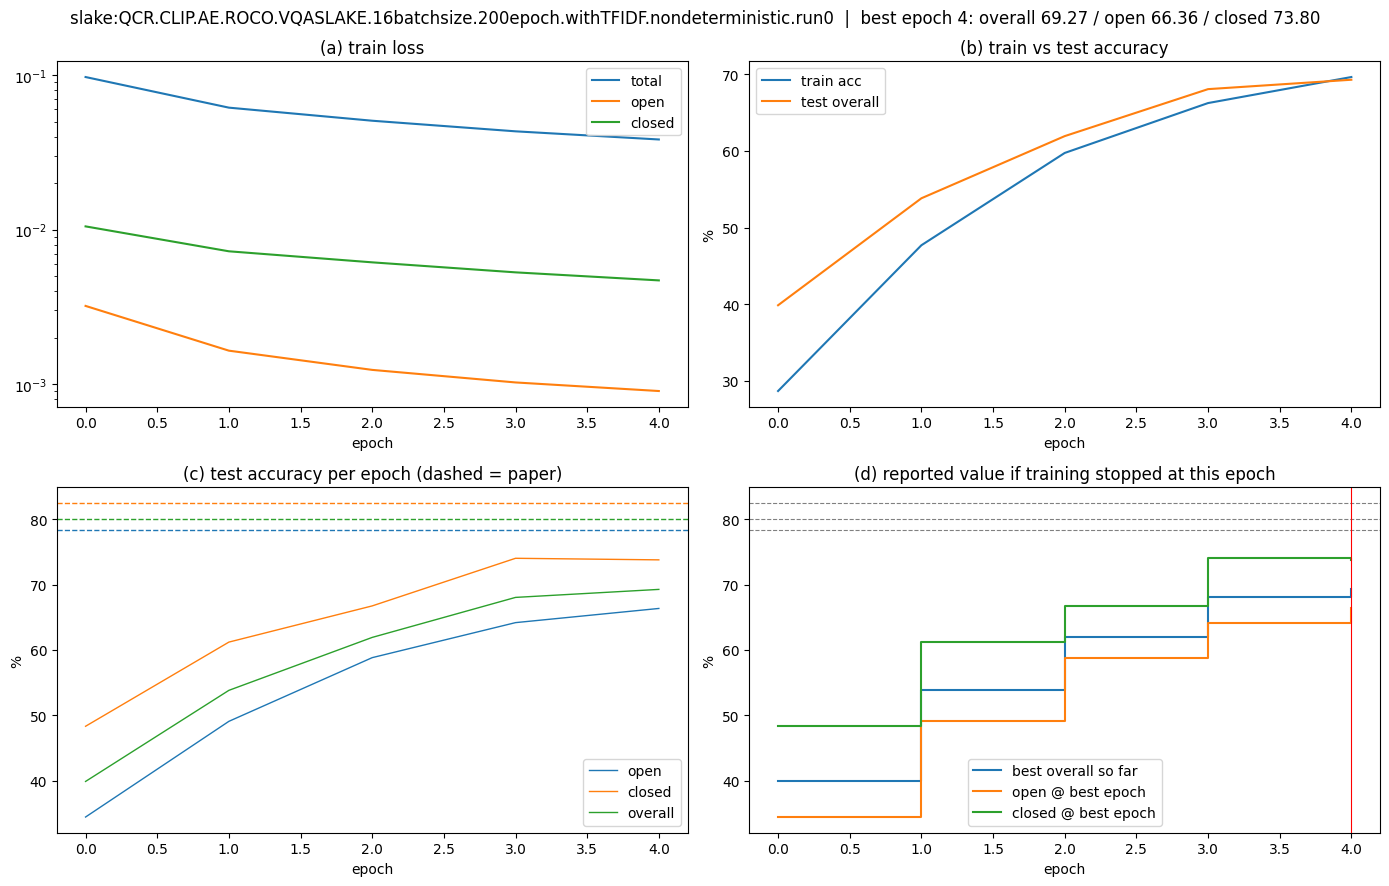

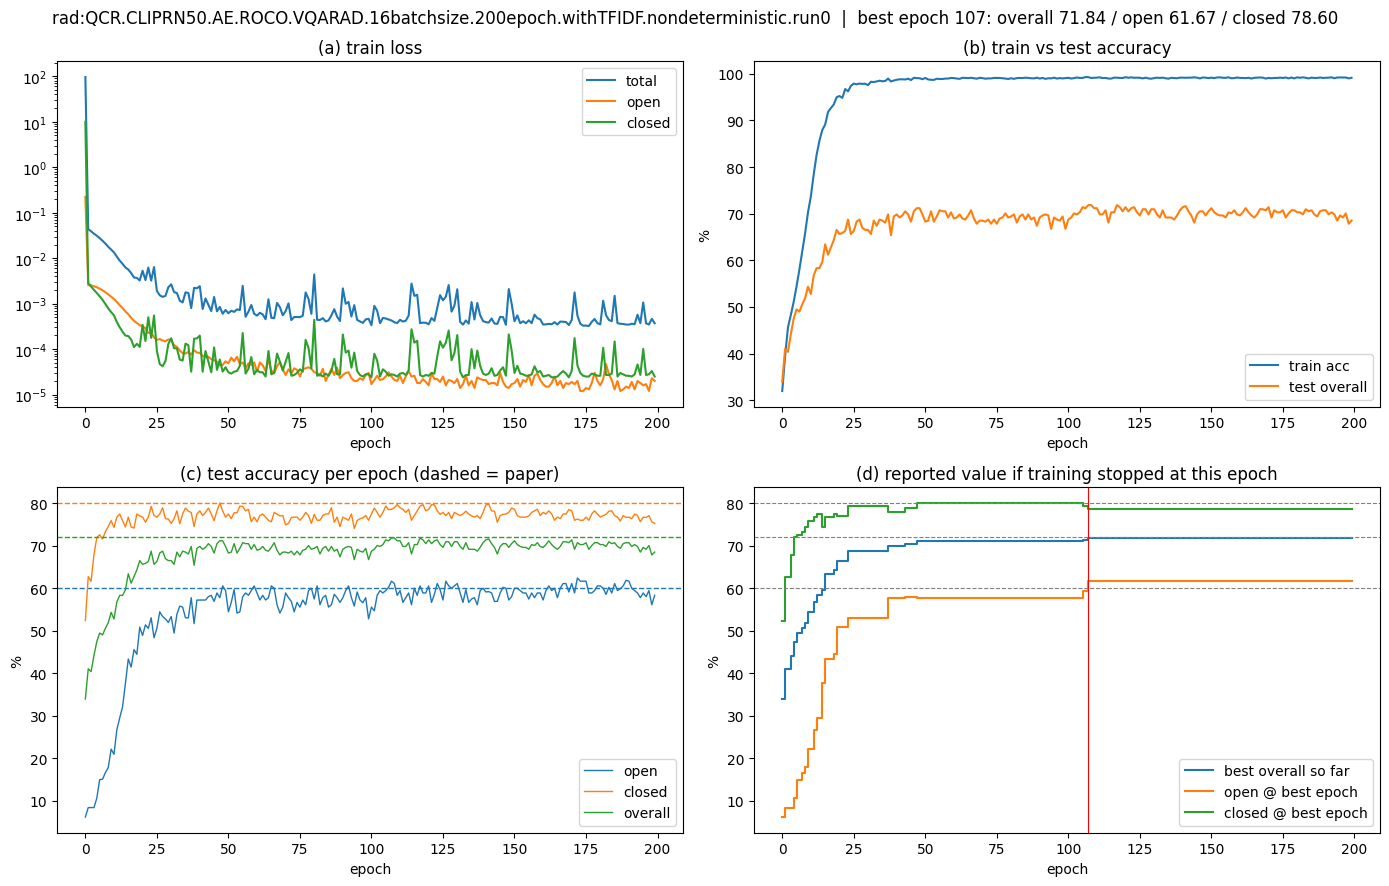

saved to /content/qcr_repro/analysis


In [ ]:
import re, json, zipfile
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

LOG_ROOT = Path('/content/qcr_repro')   # 이 폴더 아래의 모든 medVQA.log를 찾습니다
EXTRA_LOGS = []                          # 셀 출력을 txt로 저장했다면: [('rad', '/content/rad_console.txt')]
DOWNLOAD = False                         # True면 analysis 폴더를 zip으로 내려받습니다
PAPER = {'rad': (60.1, 80.0, 72.1), 'slake': (78.4, 82.5, 80.1)}   # Open, Closed, Overall
OUT = LOG_ROOT / 'analysis'
OUT.mkdir(parents=True, exist_ok=True)

_EPOCH = re.compile(r'\[Epoch\]:(\d+)')
_TRAIN = re.compile(r'\[Train\] Loss:([-\d.eE+]+) , Train_Acc:([-\d.eE+]+)%')
_SUB = re.compile(r'\[Train\] Loss_Open:([-\d.eE+]+) , Loss_Close:([-\d.eE+]+)')
_VAL = re.compile(r'\[Validate\] Val_Acc:([\d.]+)%\s*\|\s*Open_ACC:([\d.]+)%\s*\|\s*Close_ACC:([\d.]+)%')


def parse_epochs(text):
    """epoch마다 한 행. 로그가 중간에 다시 시작됐으면 마지막 실행만 남깁니다."""
    rows, cur = [], None
    for line in text.splitlines():
        if m := _EPOCH.search(line):
            if int(m[1]) == 0:
                rows = []
            cur = {'epoch': int(m[1])}
        elif cur is None:
            continue
        elif m := _TRAIN.search(line):
            cur.update(train_loss=float(m[1]), train_acc=float(m[2]))
        elif m := _SUB.search(line):
            cur.update(loss_open=float(m[1]), loss_closed=float(m[2]))
        elif m := _VAL.search(line):
            cur.update(test_overall=float(m[1]), test_open=float(m[2]), test_closed=float(m[3]))
            rows.append(cur)
            cur = None
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    # 지금까지의 최고 epoch: train.py와 같이 overall이 '처음으로 더 높아진' epoch
    best_i, best = [], -1.0
    for i, v in enumerate(df['test_overall']):
        if v > best:
            best, bi = v, i
        best_i.append(bi)
    for k in ('overall', 'open', 'closed'):
        df[f'best_{k}'] = df[f'test_{k}'].iloc[best_i].values
    df['best_epoch'] = df['epoch'].iloc[best_i].values
    df['gap'] = df['train_acc'] - df['test_overall']
    return df


def dataset_of(path):
    s = str(path).upper()
    return 'slake' if 'SLAKE' in s else 'rad' if 'RAD' in s else 'unknown'


logs = [(dataset_of(p), p) for p in sorted(LOG_ROOT.rglob('medVQA.log'))]
logs += [(d, Path(p)) for d, p in EXTRA_LOGS]
runs = []
for dataset, path in logs:
    df = parse_epochs(path.read_text(encoding='utf-8', errors='replace'))
    if df.empty:
        print('no epochs in', path); continue
    df.to_csv(OUT / f'epochs_{dataset}_{path.parent.name}.csv', index=False)
    runs.append({'dataset': dataset, 'name': f'{dataset}:{path.parent.name}', 'path': path, 'df': df})
assert runs, f'{LOG_ROOT} 아래에서 medVQA.log를 찾지 못했습니다'


def run_summary(r):
    df, p = r['df'], PAPER.get(r['dataset'], (float('nan'),) * 3)
    b, last = df.loc[df['epoch'] == df['best_epoch'].iloc[-1]].iloc[0], df.iloc[-1]
    tail = df.tail(min(10, len(df)))
    near = df.loc[df['test_overall'] >= b['test_overall'] - 1.0, 'epoch'].iloc[0]
    return {'dataset': r['dataset'], 'run': r['path'].parent.name, 'epochs': len(df),
            'best_epoch': int(b['epoch']), 'best_open': b['test_open'], 'best_closed': b['test_closed'],
            'best_overall': b['test_overall'], 'paper_overall': p[2], 'delta_overall': b['test_overall'] - p[2],
            'last_open': last['test_open'], 'last_closed': last['test_closed'], 'last_overall': last['test_overall'],
            'last10_mean_overall': tail['test_overall'].mean(), 'last10_std_overall': tail['test_overall'].std(ddof=0),
            'max_open (epoch)': f"{df['test_open'].max():.2f} ({int(df.loc[df['test_open'].idxmax(), 'epoch'])})",
            'max_closed (epoch)': f"{df['test_closed'].max():.2f} ({int(df.loc[df['test_closed'].idxmax(), 'epoch'])})",
            'first_epoch_within_1pt_of_best': int(near),
            'final_train_acc': last['train_acc'], 'final_gap': last['gap']}


table = pd.DataFrame([run_summary(r) for r in runs])
table.to_csv(OUT / 'run_summary.csv', index=False)
display(Markdown('### 실행별 요약\n'
                 '- best = 저자 코드 방식(test overall 최고 epoch). max_open / max_closed는 서로 다른 epoch일 수 있어 보고값이 아닙니다.\n'
                 '- gap = 마지막 epoch의 train accuracy - test overall'))
display(table.round(2))

agg = table.groupby('dataset')[['best_open', 'best_closed', 'best_overall', 'last_overall']].agg(['mean', 'std', 'count'])
display(Markdown('### 데이터셋별 평균 (실행이 여러 개일 때 의미 있음)'))
display(agg.round(2))

for r in runs:
    df, p = r['df'], PAPER.get(r['dataset'])
    fig, ax = plt.subplots(2, 2, figsize=(14, 9))
    fig.suptitle(f"{r['name']}  |  best epoch {int(df['best_epoch'].iloc[-1])}: "
                 f"overall {df['best_overall'].iloc[-1]:.2f} / open {df['best_open'].iloc[-1]:.2f} / closed {df['best_closed'].iloc[-1]:.2f}")
    a = ax[0, 0]
    for col, lab in (('train_loss', 'total'), ('loss_open', 'open'), ('loss_closed', 'closed')):
        if col in df: a.plot(df['epoch'], df[col], label=lab)
    a.set_yscale('log'); a.set_title('(a) train loss'); a.set_xlabel('epoch'); a.legend()
    a = ax[0, 1]
    a.plot(df['epoch'], df['train_acc'], label='train acc')
    a.plot(df['epoch'], df['test_overall'], label='test overall')
    a.set_title('(b) train vs test accuracy'); a.set_xlabel('epoch'); a.set_ylabel('%'); a.legend()
    a = ax[1, 0]
    for col, lab, k in (('test_open', 'open', 0), ('test_closed', 'closed', 1), ('test_overall', 'overall', 2)):
        line, = a.plot(df['epoch'], df[col], label=lab, lw=1)
        if p: a.axhline(p[k], ls='--', color=line.get_color(), lw=1)
    a.set_title('(c) test accuracy per epoch (dashed = paper)'); a.set_xlabel('epoch'); a.set_ylabel('%'); a.legend()
    a = ax[1, 1]
    a.step(df['epoch'], df['best_overall'], where='post', label='best overall so far')
    a.step(df['epoch'], df['best_open'], where='post', label='open @ best epoch')
    a.step(df['epoch'], df['best_closed'], where='post', label='closed @ best epoch')
    if p:
        for k in range(3): a.axhline(p[k], ls='--', color='gray', lw=0.8)
    a.axvline(df['best_epoch'].iloc[-1], color='red', lw=0.8)
    a.set_title('(d) reported value if training stopped at this epoch'); a.set_xlabel('epoch'); a.set_ylabel('%'); a.legend()
    fig.tight_layout()
    fig.savefig(OUT / f"curves_{r['dataset']}_{r['path'].parent.name}.png", dpi=120)
    plt.show()

for dataset in sorted({r['dataset'] for r in runs}):
    group = [r for r in runs if r['dataset'] == dataset]
    if len(group) < 2:
        continue
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    wide = pd.concat({r['name']: r['df'].set_index('epoch')['test_overall'] for r in group}, axis=1)
    best = pd.concat({r['name']: r['df'].set_index('epoch')['best_overall'] for r in group}, axis=1)
    for frame, a, title in ((wide, ax[0], 'test overall per epoch'), (best, ax[1], 'best overall so far')):
        for c in frame: a.plot(frame.index, frame[c], lw=0.6, alpha=0.5)
        m, s = frame.mean(axis=1), frame.std(axis=1)
        a.plot(m.index, m, color='black', label=f'mean of {len(group)} runs')
        a.fill_between(m.index, m - s, m + s, color='black', alpha=0.15, label='±1 std')
        if dataset in PAPER: a.axhline(PAPER[dataset][2], ls='--', color='red', label='paper overall')
        a.set_title(f'{dataset}: {title}'); a.set_xlabel('epoch'); a.set_ylabel('%'); a.legend()
    fig.tight_layout()
    fig.savefig(OUT / f'runs_overlay_{dataset}.png', dpi=120)
    plt.show()

print('saved to', OUT)
if DOWNLOAD:
    from google.colab import files
    archive = Path('/content/qcr_analysis.zip')
    with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_DEFLATED) as z:
        for f in OUT.iterdir():
            z.write(f, f.name)
    files.download(str(archive))


(a) train loss

(b) train accuracy와 test accuracy

(c) epoch별 test 정확도와 논문 값

(d) 그 epoch에서 멈췄다면 보고됐을 값

In [ ]:
import re
from pathlib import Path
import pandas as pd
from IPython.display import Markdown, display

LOG_ROOT = Path('/content/qcr_repro')    # 이 폴더 아래의 medVQA.log를 모두 찾습니다
CUTOFFS = [25,50, 100, 200]                 # 앞에서부터 N epoch까지만 본 결과
PAPER = {'rad': (60.1, 80.0, 72.1), 'slake': (78.4, 82.5, 80.1)}   # Open, Closed, Overall
MIN_EPOCHS = 25                         # 이보다 짧은 로그(quick check 등)는 제외

_EPOCH = re.compile(r'\[Epoch\]:(\d+)')
_VAL = re.compile(r'\[Validate\] Val_Acc:([\d.]+)%\s*\|\s*Open_ACC:([\d.]+)%\s*\|\s*Close_ACC:([\d.]+)%')


def read_epochs(path):
    """epoch별 test 정확도. 로그가 epoch 0부터 다시 시작됐으면 마지막 실행만 남깁니다."""
    rows, ep = [], None
    for line in path.read_text(encoding='utf-8', errors='replace').splitlines():
        if m := _EPOCH.search(line):
            ep = int(m[1])
            if ep == 0:
                rows = []
        elif m := _VAL.search(line):
            rows.append({'epoch': ep if ep is not None else len(rows),
                         'overall': float(m[1]), 'open': float(m[2]), 'closed': float(m[3])})
            ep = None
    return rows


def best_of(rows):
    """train.py와 같은 방식: overall이 처음으로 더 높아진 epoch."""
    best = None
    for r in rows:
        if r['overall'] > (best['overall'] if best else 0):
            best = r
    return best


table = []
for path in sorted(LOG_ROOT.rglob('medVQA.log')):
    name = path.parent.name
    dataset = 'slake' if 'SLAKE' in name.upper() else 'rad' if 'RAD' in name.upper() else '?'
    rows = read_epochs(path)
    if len(rows) < MIN_EPOCHS:
        print(f'skip {name} ({len(rows)} epochs)')
        continue
    p_open, p_closed, p_overall = PAPER.get(dataset, (float('nan'),) * 3)
    for n in CUTOFFS:
        if n > len(rows):
            print(f'{name}: {len(rows)} epoch만 있어서 {n} epoch 기준은 생략')
            continue
        cut = rows[:n]
        b, last = best_of(cut), cut[-1]
        table.append({
            'dataset': dataset, 'epochs': n, 'best_epoch': b['epoch'],
            'best_open': b['open'], 'best_closed': b['closed'], 'best_overall': b['overall'],
            'paper_overall': p_overall, 'delta_overall': b['overall'] - p_overall,
            'last_open': last['open'], 'last_closed': last['closed'], 'last_overall': last['overall'],
            'run': name,
        })

df = pd.DataFrame(table)
if df.empty:
    print('사용할 로그가 없습니다:', LOG_ROOT)
else:
    lines = ['|Dataset|Epochs|Best epoch|Open|Closed|Overall|Paper overall|Delta|Last-epoch overall|',
             '|---|---:|---:|---:|---:|---:|---:|---:|---:|']
    for r in df.itertuples():
        lines.append(f'|{r.dataset}|{r.epochs}|{r.best_epoch}|{r.best_open:.2f}|{r.best_closed:.2f}|'
                     f'{r.best_overall:.2f}|{r.paper_overall:.1f}|{r.delta_overall:+.2f}|{r.last_overall:.2f}|')
    display(Markdown('\n'.join(lines)))
    df.to_csv(LOG_ROOT / 'epoch_cutoff_summary.csv', index=False)
    print('saved to', LOG_ROOT / 'epoch_cutoff_summary.csv')

skip QCR.CLIP.AE.ROCO.VQASLAKE.16batchsize.200epoch.withTFIDF.nondeterministic.run0 (12 epochs)


|Dataset|Epochs|Best epoch|Open|Closed|Overall|Paper overall|Delta|Last-epoch overall|
|---|---:|---:|---:|---:|---:|---:|---:|---:|
|rad|25|23|53.04|79.26|68.74|72.1|-3.36|65.63|
|rad|50|47|57.78|80.07|71.18|72.1|-0.92|69.84|
|rad|100|47|57.78|80.07|71.18|72.1|-0.92|66.74|
|rad|200|107|61.67|78.60|71.84|72.1|-0.26|68.51|

saved to /content/qcr_repro/epoch_cutoff_summary.csv


In [ ]:
import json, subprocess, time
from pathlib import Path

# 1) 기존 200 epoch 학습 프로세스 종료
subprocess.run(['pkill', '-f', 'repro_slake.run0.yaml'])
time.sleep(10)
assert subprocess.run(['pgrep', '-f', 'repro_slake.run0.yaml'], capture_output=True).returncode != 0, \
    '이전 학습이 아직 살아 있습니다. 이 셀을 다시 실행하세요.'
print('이전 학습 종료 확인')

# 2) 50 epoch 학습 (config 이름 repro_slake.run0.epochs50.yaml, 로그 폴더도 따로 생김)
DATASET, N_EPOCH = 'slake', 50
results_path = WORK / 'slake_results.json'
if DATASET not in CLIP_WEIGHTS:
    qcr_port.prepare_data(QCR, DATASET, CACHE)
    CLIP_WEIGHTS[DATASET] = qcr_port.fetch(qcr_port.RUNS[DATASET]['encoder'], CACHE)
print('start', time.strftime('%H:%M:%S UTC'))
result = qcr_port.train(QCR, DATASET, CLIP_WEIGHTS[DATASET], 0, n_epoch=N_EPOCH)
results_path.write_text(json.dumps([result], indent=2), encoding='utf-8')

# 3) 결과 출력 (아침에 Ctrl+S 하면 로컬 노트북에도 남음)
print('end', time.strftime('%H:%M:%S UTC'))
paper = result['paper_open_closed_overall']
for k, name in enumerate(('open', 'closed', 'overall')):
    print(f"{name:8s} best {result['best'][name]:6.2f} (epoch {result['best']['epoch']})  "
          f"last {result['last'][name]:6.2f}  paper {paper[k]}  delta {result['best'][name] - paper[k]:+.2f}")
print('\n===SLAKE_RESULTS_JSON===')
print(json.dumps([result], indent=2))


이전 학습 종료 확인
start 19:01:33 UTC
$ /usr/bin/python3 main/main.py --cfg configs/repro_slake.run0.epochs50.yaml
I0000 00:00:1793991699.996486   86505 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793991702.462577   86505 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
loading dictionary from ./data/data_slake/dictionary.pkl
loading DAE image data from file: ./data/data_slake/images128x128.pkl
loading CLIP image data from file: ./data/data_slake/images250x250.pkl
loading DAE image data from file: ./data/data_slake/images128x128.pkl
loading CLIP image data from file: ./data/data_slake/images250x250.pkl
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is depr

: 

In [87]:
import re, os, time
log = '/content/qcr_repro/PubMedCLIP/QCR_PubMedCLIP/output/qcr/clip_ae/roco/VQASLAKE/QCR.CLIP.AE.ROCO.VQASLAKE.16batchsize.200epoch.withTFIDF.nondeterministic.run0.epochs50/medVQA.log'
VAL_RE = re.compile(r'\[Validate\] Val_Acc:([\d.]+)%\s*\|\s*Open_ACC:([\d.]+)%\s*\|\s*Close_ACC:([\d.]+)%')
rows = [tuple(map(float, m)) for m in VAL_RE.findall(open(log, encoding='utf-8', errors='replace').read())]
print('완료 epoch:', len(rows), '/ 50')
print('로그 마지막 수정:', round(time.time() - os.path.getmtime(log)), '초 전')
if rows:
    i = max(range(len(rows)), key=lambda k: (rows[k][0], -k))  # train.py처럼 overall 최고 중 가장 이른 epoch
    print(f'best epoch {i}: overall {rows[i][0]}  open {rows[i][1]}  closed {rows[i][2]}')
    print(f'last epoch {len(rows)-1}: overall {rows[-1][0]}  open {rows[-1][1]}  closed {rows[-1][2]}')


완료 epoch: 50 / 50
로그 마지막 수정: 98 초 전
best epoch 38: overall 80.018852  open 78.637772  closed 82.168678
last epoch 49: overall 78.416588  open 76.589149  closed 81.25


skip quick check QCR.CLIP.AE.ROCO.VQASLAKE.16batchsize.200epoch.withTFIDF.nondeterministic.run0.epochs50


### SLAKE 실행별 요약
- best = 저자 코드 방식(test overall 최고 epoch). max_open / max_closed는 서로 다른 epoch일 수 있어 보고값이 아닙니다.
- gap = 마지막 epoch의 train accuracy - test overall
- epochs < 200이면 학습 중이거나 중간에 끊긴 로그입니다.

,dataset,run,epochs,best_epoch,best_open,best_closed,best_overall,paper_overall,delta_overall,last_open,last_closed,last_overall,last10_mean_overall,last10_std_overall,max_open (epoch),max_closed (epoch),first_epoch_within_1pt_of_best,final_train_acc,final_gap
0,slake,QCR.CLIP.AE.ROCO.VQASLAKE.16batchsize.200epoch...,7,23,77.67,83.17,79.83,80.1,-0.27,78.29,80.53,79.17,68.09,13.92,78.29 (25),83.17 (23),23,93.66,14.49


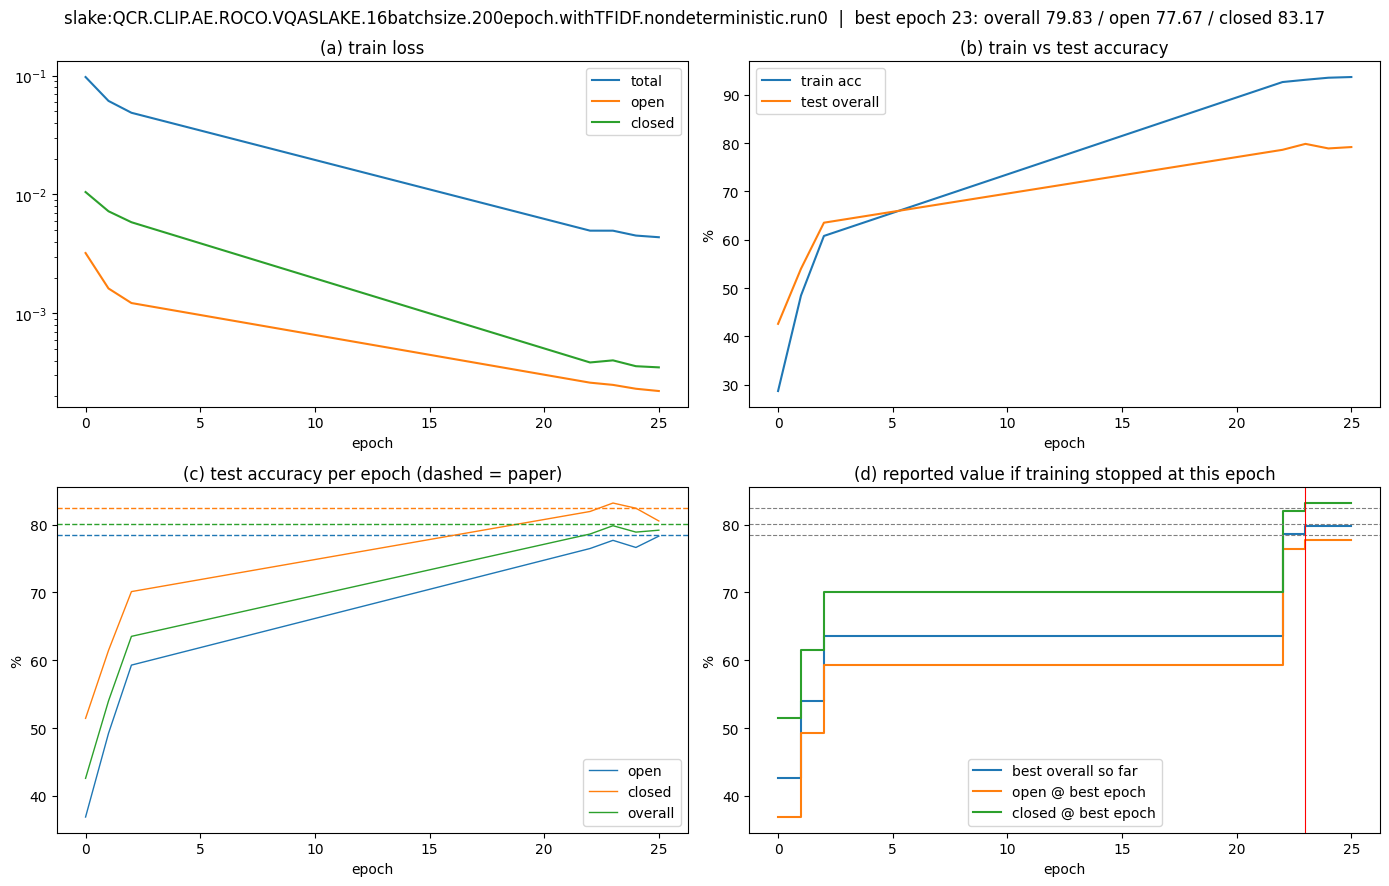

saved to /content/qcr_repro/analysis_slake


In [76]:
import re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

LOG_ROOT = Path('/content/qcr_repro')     # 이 폴더 아래의 SLAKE medVQA.log만 찾습니다
DATASET = 'slake'
PAPER = (78.4, 82.5, 80.1)                # SLAKE 논문 값: Open, Closed, Overall
SKIP_QUICK_CHECK = True                   # 이름에 '.epochsN'이 붙은 quick check 실행은 제외
OUT = LOG_ROOT / 'analysis_slake'         # rad의 analysis 폴더와 분리
OUT.mkdir(parents=True, exist_ok=True)

_EPOCH = re.compile(r'\[Epoch\]:(\d+)')
_TRAIN = re.compile(r'\[Train\] Loss:([-\d.eE+]+) , Train_Acc:([-\d.eE+]+)%')
_SUB = re.compile(r'\[Train\] Loss_Open:([-\d.eE+]+) , Loss_Close:([-\d.eE+]+)')
_VAL = re.compile(r'\[Validate\] Val_Acc:([\d.]+)%\s*\|\s*Open_ACC:([\d.]+)%\s*\|\s*Close_ACC:([\d.]+)%')


def parse_epochs(text):
    """epoch마다 한 행. 로그가 중간에 다시 시작됐으면 마지막 실행만 남깁니다."""
    rows, cur = [], None
    for line in text.splitlines():
        if m := _EPOCH.search(line):
            if int(m[1]) == 0:
                rows = []
            cur = {'epoch': int(m[1])}
        elif cur is None:
            continue
        elif m := _TRAIN.search(line):
            cur.update(train_loss=float(m[1]), train_acc=float(m[2]))
        elif m := _SUB.search(line):
            cur.update(loss_open=float(m[1]), loss_closed=float(m[2]))
        elif m := _VAL.search(line):
            cur.update(test_overall=float(m[1]), test_open=float(m[2]), test_closed=float(m[3]))
            rows.append(cur)
            cur = None
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    # 지금까지의 최고 epoch: train.py와 같이 overall이 '처음으로 더 높아진' epoch
    best_i, best = [], -1.0
    for i, v in enumerate(df['test_overall']):
        if v > best:
            best, bi = v, i
        best_i.append(bi)
    for k in ('overall', 'open', 'closed'):
        df[f'best_{k}'] = df[f'test_{k}'].iloc[best_i].values
    df['best_epoch'] = df['epoch'].iloc[best_i].values
    df['gap'] = df['train_acc'] - df['test_overall']
    return df


runs = []
for path in sorted(LOG_ROOT.rglob('medVQA.log')):
    name = path.parent.name
    if 'SLAKE' not in name.upper():
        continue
    if SKIP_QUICK_CHECK and re.search(r'\.epochs\d+', name):
        print('skip quick check', name); continue
    df = parse_epochs(path.read_text(encoding='utf-8', errors='replace'))
    if df.empty:
        print('no epochs in', path); continue
    df.to_csv(OUT / f'epochs_{DATASET}_{name}.csv', index=False)
    runs.append({'name': name, 'path': path, 'df': df})
assert runs, f'{LOG_ROOT} 아래에서 SLAKE medVQA.log를 찾지 못했습니다'


def run_summary(r):
    df, p = r['df'], PAPER
    b, last = df.loc[df['epoch'] == df['best_epoch'].iloc[-1]].iloc[0], df.iloc[-1]
    tail = df.tail(min(10, len(df)))
    near = df.loc[df['test_overall'] >= b['test_overall'] - 1.0, 'epoch'].iloc[0]
    return {'dataset': DATASET, 'run': r['name'], 'epochs': len(df),
            'best_epoch': int(b['epoch']), 'best_open': b['test_open'], 'best_closed': b['test_closed'],
            'best_overall': b['test_overall'], 'paper_overall': p[2], 'delta_overall': b['test_overall'] - p[2],
            'last_open': last['test_open'], 'last_closed': last['test_closed'], 'last_overall': last['test_overall'],
            'last10_mean_overall': tail['test_overall'].mean(), 'last10_std_overall': tail['test_overall'].std(ddof=0),
            'max_open (epoch)': f"{df['test_open'].max():.2f} ({int(df.loc[df['test_open'].idxmax(), 'epoch'])})",
            'max_closed (epoch)': f"{df['test_closed'].max():.2f} ({int(df.loc[df['test_closed'].idxmax(), 'epoch'])})",
            'first_epoch_within_1pt_of_best': int(near),
            'final_train_acc': last['train_acc'], 'final_gap': last['gap']}


table = pd.DataFrame([run_summary(r) for r in runs])
table.to_csv(OUT / 'slake_run_summary.csv', index=False)
display(Markdown('### SLAKE 실행별 요약\n'
                 '- best = 저자 코드 방식(test overall 최고 epoch). max_open / max_closed는 서로 다른 epoch일 수 있어 보고값이 아닙니다.\n'
                 '- gap = 마지막 epoch의 train accuracy - test overall\n'
                 '- epochs < 200이면 학습 중이거나 중간에 끊긴 로그입니다.'))
display(table.round(2))

if len(runs) > 1:
    agg = table[['best_open', 'best_closed', 'best_overall', 'last_overall']].agg(['mean', 'std', 'count'])
    display(Markdown('### SLAKE 실행 평균'))
    display(agg.round(2))

for r in runs:
    df, p = r['df'], PAPER
    fig, ax = plt.subplots(2, 2, figsize=(14, 9))
    fig.suptitle(f"slake:{r['name']}  |  best epoch {int(df['best_epoch'].iloc[-1])}: "
                 f"overall {df['best_overall'].iloc[-1]:.2f} / open {df['best_open'].iloc[-1]:.2f} / closed {df['best_closed'].iloc[-1]:.2f}")
    a = ax[0, 0]
    for col, lab in (('train_loss', 'total'), ('loss_open', 'open'), ('loss_closed', 'closed')):
        if col in df: a.plot(df['epoch'], df[col], label=lab)
    a.set_yscale('log'); a.set_title('(a) train loss'); a.set_xlabel('epoch'); a.legend()
    a = ax[0, 1]
    a.plot(df['epoch'], df['train_acc'], label='train acc')
    a.plot(df['epoch'], df['test_overall'], label='test overall')
    a.set_title('(b) train vs test accuracy'); a.set_xlabel('epoch'); a.set_ylabel('%'); a.legend()
    a = ax[1, 0]
    for col, lab, k in (('test_open', 'open', 0), ('test_closed', 'closed', 1), ('test_overall', 'overall', 2)):
        line, = a.plot(df['epoch'], df[col], label=lab, lw=1)
        a.axhline(p[k], ls='--', color=line.get_color(), lw=1)
    a.set_title('(c) test accuracy per epoch (dashed = paper)'); a.set_xlabel('epoch'); a.set_ylabel('%'); a.legend()
    a = ax[1, 1]
    a.step(df['epoch'], df['best_overall'], where='post', label='best overall so far')
    a.step(df['epoch'], df['best_open'], where='post', label='open @ best epoch')
    a.step(df['epoch'], df['best_closed'], where='post', label='closed @ best epoch')
    for k in range(3): a.axhline(p[k], ls='--', color='gray', lw=0.8)
    a.axvline(df['best_epoch'].iloc[-1], color='red', lw=0.8)
    a.set_title('(d) reported value if training stopped at this epoch'); a.set_xlabel('epoch'); a.set_ylabel('%'); a.legend()
    fig.tight_layout()
    fig.savefig(OUT / f"curves_{DATASET}_{r['name']}.png", dpi=120)
    plt.show()

if len(runs) > 1:
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    wide = pd.concat({r['name']: r['df'].set_index('epoch')['test_overall'] for r in runs}, axis=1)
    best = pd.concat({r['name']: r['df'].set_index('epoch')['best_overall'] for r in runs}, axis=1)
    for frame, a, title in ((wide, ax[0], 'test overall per epoch'), (best, ax[1], 'best overall so far')):
        for c in frame: a.plot(frame.index, frame[c], lw=0.6, alpha=0.5)
        m, s = frame.mean(axis=1), frame.std(axis=1)
        a.plot(m.index, m, color='black', label=f'mean of {len(runs)} runs')
        a.fill_between(m.index, m - s, m + s, color='black', alpha=0.15, label='±1 std')
        a.axhline(PAPER[2], ls='--', color='red', label='paper overall')
        a.set_title(f'slake: {title}'); a.set_xlabel('epoch'); a.set_ylabel('%'); a.legend()
    fig.tight_layout()
    fig.savefig(OUT / 'runs_overlay_slake.png', dpi=120)
    plt.show()

print('saved to', OUT)


In [88]:
import re
from pathlib import Path
import pandas as pd
from IPython.display import Markdown, display

LOG_ROOT = Path('/content/qcr_repro')    # 이 폴더 아래의 SLAKE medVQA.log만 찾습니다
CUTOFFS = [25, 50, 100, 200]             # 앞에서부터 N epoch까지만 본 결과
PAPER = (78.4, 82.5, 80.1)               # SLAKE 논문 값: Open, Closed, Overall
MIN_EPOCHS = 25                          # 이보다 짧은 로그(quick check 등)는 제외
OUT_CSV = LOG_ROOT / 'slake_epoch_cutoff_summary.csv'   # rad의 epoch_cutoff_summary.csv와 분리

_EPOCH = re.compile(r'\[Epoch\]:(\d+)')
_VAL = re.compile(r'\[Validate\] Val_Acc:([\d.]+)%\s*\|\s*Open_ACC:([\d.]+)%\s*\|\s*Close_ACC:([\d.]+)%')


def read_epochs(path):
    """epoch별 test 정확도. 로그가 epoch 0부터 다시 시작됐으면 마지막 실행만 남깁니다."""
    rows, ep = [], None
    for line in path.read_text(encoding='utf-8', errors='replace').splitlines():
        if m := _EPOCH.search(line):
            ep = int(m[1])
            if ep == 0:
                rows = []
        elif m := _VAL.search(line):
            rows.append({'epoch': ep if ep is not None else len(rows),
                         'overall': float(m[1]), 'open': float(m[2]), 'closed': float(m[3])})
            ep = None
    return rows


def best_of(rows):
    """train.py와 같은 방식: overall이 처음으로 더 높아진 epoch."""
    best = None
    for r in rows:
        if r['overall'] > (best['overall'] if best else 0):
            best = r
    return best


table = []
for path in sorted(LOG_ROOT.rglob('medVQA.log')):
    name = path.parent.name
    if 'SLAKE' not in name.upper():
        continue
    rows = read_epochs(path)
    if len(rows) < MIN_EPOCHS:
        print(f'skip {name} ({len(rows)} epochs)')
        continue
    for n in CUTOFFS:
        if n > len(rows):
            print(f'{name}: {len(rows)} epoch만 있어서 {n} epoch 기준은 생략')
            continue
        cut = rows[:n]
        b, last = best_of(cut), cut[-1]
        table.append({
            'dataset': 'slake', 'epochs': n, 'best_epoch': b['epoch'],
            'best_open': b['open'], 'best_closed': b['closed'], 'best_overall': b['overall'],
            'paper_overall': PAPER[2], 'delta_overall': b['overall'] - PAPER[2],
            'last_open': last['open'], 'last_closed': last['closed'], 'last_overall': last['overall'],
            'run': name,
        })

df = pd.DataFrame(table)
if df.empty:
    print('사용할 SLAKE 로그가 없습니다:', LOG_ROOT)
else:
    lines = ['|Dataset|Epochs|Best epoch|Open|Closed|Overall|Paper overall|Delta|Last-epoch overall|',
             '|---|---:|---:|---:|---:|---:|---:|---:|---:|']
    for r in df.itertuples():
        lines.append(f'|{r.dataset}|{r.epochs}|{r.best_epoch}|{r.best_open:.2f}|{r.best_closed:.2f}|'
                     f'{r.best_overall:.2f}|{r.paper_overall:.1f}|{r.delta_overall:+.2f}|{r.last_overall:.2f}|')
    display(Markdown('\n'.join(lines)))
    df.to_csv(OUT_CSV, index=False)
    print('saved to', OUT_CSV)


skip QCR.CLIP.AE.ROCO.VQASLAKE.16batchsize.200epoch.withTFIDF.nondeterministic.run0 (7 epochs)
QCR.CLIP.AE.ROCO.VQASLAKE.16batchsize.200epoch.withTFIDF.nondeterministic.run0.epochs50: 50 epoch만 있어서 100 epoch 기준은 생략
QCR.CLIP.AE.ROCO.VQASLAKE.16batchsize.200epoch.withTFIDF.nondeterministic.run0.epochs50: 50 epoch만 있어서 200 epoch 기준은 생략


|Dataset|Epochs|Best epoch|Open|Closed|Overall|Paper overall|Delta|Last-epoch overall|
|---|---:|---:|---:|---:|---:|---:|---:|---:|
|slake|25|16|78.76|81.49|79.83|80.1|-0.27|78.89|
|slake|50|38|78.64|82.17|80.02|80.1|-0.08|78.42|

saved to /content/qcr_repro/slake_epoch_cutoff_summary.csv
